# 02 - Time Series Analysis

## Objective

Analyse historical agricultural market prices to understand market-level reporting patterns, daily price behaviour, reporting continuity and seasonal trends.

This stage aims to:

1. Understand how many observations are reported per market per day.
2. Investigate multiple varieties and grades within the same market.
3. Identify reporting gaps and market activity patterns.
4. Develop a defensible daily price aggregation method.
5. Examine historical price trends and seasonality.
6. Identify suitable market-commodity combinations for forecasting.

**Input:** `data/processed/mandi_prices_cleaned.parquet`

**Output:** Time-series analysis findings and a prepared dataset for subsequent forecasting experiments.

In [3]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"

DATA_FILE = PROCESSED_DIR / "mandi_prices_cleaned.parquet"

con = duckdb.connect()

con.execute(f"""
    CREATE OR REPLACE VIEW prices AS
    SELECT *
    FROM read_parquet('{DATA_FILE.as_posix()}')
""")

print("Dataset loaded successfully.")
print("File exists:", DATA_FILE.exists())

Dataset loaded successfully.
File exists: True


In [4]:
daily_reporting = con.execute("""
    WITH market_days AS (
        SELECT
            Project_Commodity,
            State,
            District,
            Market,
            Parsed_Date,

            COUNT(*) AS Observations,
            COUNT(DISTINCT Variety) AS Varieties,
            COUNT(DISTINCT Grade) AS Grades

        FROM prices

        GROUP BY
            Project_Commodity,
            State,
            District,
            Market,
            Parsed_Date
    )

    SELECT
        Project_Commodity,
        COUNT(*) AS Market_Days,

        ROUND(AVG(Observations), 2)
            AS Avg_Observations_Per_Market_Day,

        MEDIAN(Observations)
            AS Median_Observations_Per_Market_Day,

        QUANTILE_CONT(Observations, 0.95)
            AS P95_Observations_Per_Market_Day,

        MAX(Observations)
            AS Max_Observations_Per_Market_Day,

        ROUND(AVG(Varieties), 2)
            AS Avg_Varieties_Per_Market_Day

    FROM market_days
    GROUP BY Project_Commodity
    ORDER BY Project_Commodity
""").df()

display(daily_reporting)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Market_Days,Avg_Observations_Per_Market_Day,Median_Observations_Per_Market_Day,P95_Observations_Per_Market_Day,Max_Observations_Per_Market_Day,Avg_Varieties_Per_Market_Day
0,Cotton,850144,1.10,1.0,2.0,7,1.10
1,Grapes,332029,1.11,1.0,2.0,9,1.09
2,Onion,3021329,1.05,1.0,1.0,12,1.05
3,Pomegranate,557537,1.03,1.0,1.0,6,1.00
4,Soybean,1116993,1.07,1.0,2.0,5,1.06
5,Tomato,2785000,1.01,1.0,1.0,6,1.01


In [5]:
multiple_observations = con.execute("""
    SELECT
        Project_Commodity,
        State,
        District,
        Market,
        Parsed_Date,
        COUNT(*) AS Observations,
        COUNT(DISTINCT Variety) AS Varieties,
        COUNT(DISTINCT Grade) AS Grades,
        COUNT(DISTINCT Modal_Price) AS Different_Modal_Prices,
        MIN(Modal_Price) AS Min_Modal_Price,
        MAX(Modal_Price) AS Max_Modal_Price
    FROM prices
    GROUP BY
        Project_Commodity,
        State,
        District,
        Market,
        Parsed_Date
    HAVING COUNT(*) > 1
    ORDER BY
        Observations DESC,
        Project_Commodity
    LIMIT 30
""").df()

display(multiple_observations)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,State,District,Market,Parsed_Date,Observations,Varieties,Grades,Different_Modal_Prices,Min_Modal_Price,Max_Modal_Price
0,Onion,Karnataka,Bangalore,Bangalore,2014-01-06,12,4,3,4,800.0,1250.0
1,Onion,Karnataka,Bangalore,Bangalore,2014-01-04,11,4,3,4,800.0,1250.0
2,Onion,Karnataka,Bangalore,Bangalore,2014-01-03,10,4,3,4,750.0,1300.0
3,Grapes,Kerala,Idukki,Kattappana,2017-09-03,9,3,3,6,5200.0,6700.0
4,Onion,Karnataka,Bangalore,Bangalore,2014-01-07,8,4,2,4,500.0,1160.0
5,Onion,Karnataka,Bangalore,Bangalore,2015-01-27,8,4,2,4,800.0,1600.0
6,Onion,Karnataka,Bangalore,Bangalore,2015-01-28,8,4,2,4,850.0,1700.0
7,Cotton,Karnataka,Haveri,Ranebennur,2009-03-27,7,4,2,4,2179.0,2980.0
8,Grapes,NCT of Delhi,Delhi,Azadpur,2006-12-25,7,3,3,6,2100.0,4500.0
9,Grapes,Kerala,Idukki,Kattappana,2015-09-19,7,3,3,7,4000.0,7200.0


In [6]:
sample_records = con.execute("""
    SELECT
        Project_Commodity,
        State,
        District,
        Market,
        Parsed_Date,
        Variety,
        Grade,
        Min_Price,
        Max_Price,
        Modal_Price
    FROM prices
    WHERE
        (
            Project_Commodity = 'Onion'
            AND State = 'Karnataka'
            AND District = 'Bangalore'
            AND Market = 'Bangalore'
            AND Parsed_Date = DATE '2014-01-06'
        )
        OR
        (
            Project_Commodity = 'Grapes'
            AND State = 'Kerala'
            AND District = 'Idukki'
            AND Market = 'Kattappana'
            AND Parsed_Date = DATE '2017-09-03'
        )
        OR
        (
            Project_Commodity = 'Grapes'
            AND State = 'NCT of Delhi'
            AND District = 'Delhi'
            AND Market = 'Azadpur'
            AND Parsed_Date = DATE '2006-12-25'
        )
    ORDER BY
        Project_Commodity,
        Market,
        Parsed_Date,
        Variety,
        Grade
""").df()

display(sample_records)

,Project_Commodity,State,District,Market,Parsed_Date,Variety,Grade,Min_Price,Max_Price,Modal_Price
0,Grapes,NCT of Delhi,Delhi,Azadpur,2006-12-25,Annabesahai,Small,2000.0,2200.0,2100.0
1,Grapes,NCT of Delhi,Delhi,Azadpur,2006-12-25,Black,Large,0.0,4750.0,4500.0
2,Grapes,NCT of Delhi,Delhi,Azadpur,2006-12-25,Black,Medium,3250.0,3750.0,3625.0
3,Grapes,NCT of Delhi,Delhi,Azadpur,2006-12-25,Black,Small,2500.0,3000.0,2750.0
4,Grapes,NCT of Delhi,Delhi,Azadpur,2006-12-25,Green,Large,3250.0,3750.0,3500.0
5,Grapes,NCT of Delhi,Delhi,Azadpur,2006-12-25,Green,Medium,2500.0,3000.0,2750.0
6,Grapes,NCT of Delhi,Delhi,Azadpur,2006-12-25,Green,Small,2000.0,2250.0,2125.0
7,Grapes,Kerala,Idukki,Kattappana,2017-09-03,Black,Large,5500.0,6000.0,5700.0
8,Grapes,Kerala,Idukki,Kattappana,2017-09-03,Black,Medium,6300.0,7000.0,6700.0
9,Grapes,Kerala,Idukki,Kattappana,2017-09-03,Black,Small,5500.0,5900.0,5700.0


In [7]:
variety_grade_summary = con.execute("""
    SELECT
        Project_Commodity,
        COUNT(DISTINCT Variety) AS Unique_Varieties,
        COUNT(DISTINCT Grade) AS Unique_Grades,
        COUNT(DISTINCT (Variety, Grade)) AS Unique_Variety_Grade_Pairs,
        COUNT(*) AS Total_Records
    FROM prices
    GROUP BY Project_Commodity
    ORDER BY Project_Commodity
""").df()

display(variety_grade_summary)

,Project_Commodity,Unique_Varieties,Unique_Grades,Unique_Variety_Grade_Pairs,Total_Records
0,Cotton,109,11,326,936024
1,Grapes,10,13,62,369772
2,Onion,26,14,178,3168401
3,Pomegranate,3,12,23,572345
4,Soybean,7,11,40,1192827
5,Tomato,6,14,62,2818498


In [8]:
grade_distribution = con.execute("""
    SELECT
        Project_Commodity,
        Variety,
        Grade,
        COUNT(*) AS Records,
        COUNT(DISTINCT State) AS States,
        COUNT(DISTINCT Market) AS Markets,
        COUNT(DISTINCT Modal_Price) AS Distinct_Modal_Prices
    FROM prices
    GROUP BY
        Project_Commodity,
        Variety,
        Grade
    ORDER BY
        Project_Commodity,
        Records DESC
""").df()

display(grade_distribution.head(40))

,Project_Commodity,Variety,Grade,Records,States,Markets,Distinct_Modal_Prices
0,Cotton,Other,FAQ,311479,24,807,8838
1,Cotton,American,FAQ,92845,9,131,6651
2,Cotton,Cotton (Unginned),FAQ,78880,11,183,3838
3,Cotton,Desi,FAQ,63447,13,226,5549
4,Cotton,Shanker 6 (B) 30mm FIne,FAQ,43418,3,60,2874
5,Cotton,Kapas (Adoni),FAQ,36281,8,150,1081
6,Cotton,Cotton (Unginned),Medium,30154,2,107,1048
7,Cotton,MCU 5,FAQ,25947,6,72,1809
8,Cotton,H4,FAQ,20328,5,72,2616
9,Cotton,Other,Medium,11967,5,82,906


In [9]:
grade_price_analysis = con.execute("""
    WITH variety_day AS (
        SELECT
            Project_Commodity,
            State,
            District,
            Market,
            Parsed_Date,
            Variety,
            COUNT(*) AS Grade_Records,
            COUNT(DISTINCT Grade) AS Grades,
            COUNT(DISTINCT Modal_Price) AS Distinct_Prices
        FROM prices
        GROUP BY
            Project_Commodity,
            State,
            District,
            Market,
            Parsed_Date,
            Variety
        HAVING COUNT(DISTINCT Grade) > 1
    )
    SELECT
        Project_Commodity,
        COUNT(*) AS Variety_Market_Days_With_Multiple_Grades,
        SUM(Grade_Records) AS Records_In_These_Groups,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE Distinct_Prices = 1
            ) / COUNT(*),
            2
        ) AS Pct_Groups_With_Identical_Prices,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE Distinct_Prices > 1
            ) / COUNT(*),
            2
        ) AS Pct_Groups_With_Different_Prices
    FROM variety_day
    GROUP BY Project_Commodity
    ORDER BY Project_Commodity
""").df()

display(grade_price_analysis)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Variety_Market_Days_With_Multiple_Grades,Records_In_These_Groups,Pct_Groups_With_Identical_Prices,Pct_Groups_With_Different_Prices
0,Cotton,1538,3076.0,51.04,48.96
1,Grapes,5275,12602.0,14.90,85.10
2,Onion,10391,20791.0,20.31,79.69
3,Pomegranate,7808,22187.0,9.32,90.68
4,Soybean,4022,8044.0,62.78,37.22
5,Tomato,8262,16524.0,12.83,87.17


In [10]:
series_coverage = con.execute("""
    SELECT
        Project_Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        COUNT(*) AS Observations,
        COUNT(DISTINCT Parsed_Date) AS Reporting_Days,
        MIN(Parsed_Date) AS First_Date,
        MAX(Parsed_Date) AS Last_Date,
        DATE_DIFF(
            'day',
            MIN(Parsed_Date),
            MAX(Parsed_Date)
        ) + 1 AS Calendar_Span_Days,
        ROUND(
            100.0 * COUNT(DISTINCT Parsed_Date) /
            NULLIF(
                DATE_DIFF(
                    'day',
                    MIN(Parsed_Date),
                    MAX(Parsed_Date)
                ) + 1,
                0
            ),
            2
        ) AS Calendar_Coverage_Pct
    FROM prices
    GROUP BY
        Project_Commodity,
        State,
        District,
        Market,
        Variety,
        Grade
    ORDER BY
        Project_Commodity,
        Reporting_Days DESC
""").df()

display(series_coverage.head(30))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,State,District,Market,Variety,Grade,Observations,Reporting_Days,First_Date,Last_Date,Calendar_Span_Days,Calendar_Coverage_Pct
0,Cotton,Gujarat,Amreli,Amreli,Other,FAQ,5634,5634,2003-04-05,2025-11-04,8250,68.29
1,Cotton,Karnataka,Bijapur,Bijapur,LH-1556,FAQ,4207,4207,2002-03-06,2025-03-01,8397,50.10
2,Cotton,Gujarat,Bhavnagar,Bhavnagar,Other,FAQ,3984,3984,2003-03-26,2025-10-27,8252,48.28
3,Cotton,Gujarat,Chhota Udaipur,Bodeliu,Shanker 6 (B) 30mm FIne,FAQ,3902,3902,2003-02-14,2025-11-05,8301,47.01
4,Cotton,Karnataka,Raichur,Raichur,F-1054,FAQ,3731,3731,2005-01-07,2025-05-05,7424,50.26
5,Cotton,Gujarat,Mehsana,Visnagar,Other,FAQ,3718,3718,2004-11-18,2025-11-03,7656,48.56
6,Cotton,Rajasthan,Ganganagar,Sriganganagar (Grain),American,FAQ,3639,3639,2002-02-01,2025-11-04,8678,41.93
7,Cotton,Telangana,Khammam,Khammam,Cotton (Unginned),FAQ,3637,3637,2005-11-22,2025-10-28,7281,49.95
8,Cotton,Madhya Pradesh,Badwani,Sendhwa,H4,FAQ,3614,3614,2007-02-19,2023-12-20,6149,58.77
9,Cotton,Tamil Nadu,Madurai,Thirumangalam,MCU 5,FAQ,3598,3598,2005-09-29,2024-06-13,6833,52.66


In [11]:
coverage_summary = (
    series_coverage
    .groupby("Project_Commodity")
    .agg(
        Total_Series=("Reporting_Days", "count"),
        Median_Reporting_Days=("Reporting_Days", "median"),
        P75_Reporting_Days=(
            "Reporting_Days",
            lambda x: x.quantile(0.75)
        ),
        P90_Reporting_Days=(
            "Reporting_Days",
            lambda x: x.quantile(0.90)
        ),
        Max_Reporting_Days=("Reporting_Days", "max"),
        Median_Calendar_Coverage=(
            "Calendar_Coverage_Pct", "median"
        )
    )
    .reset_index()
)

for threshold in [365, 730, 1000, 1500]:
    eligible = (
        series_coverage
        .assign(
            eligible=series_coverage["Reporting_Days"] >= threshold
        )
        .groupby("Project_Commodity")["eligible"]
        .sum()
        .rename(f"Series_At_Least_{threshold}_Days")
    )

    coverage_summary = coverage_summary.merge(
        eligible,
        on="Project_Commodity"
    )

display(coverage_summary.round(2))

,Project_Commodity,Total_Series,Median_Reporting_Days,P75_Reporting_Days,P90_Reporting_Days,Max_Reporting_Days,Median_Calendar_Coverage,Series_At_Least_365_Days,Series_At_Least_730_Days,Series_At_Least_1000_Days,Series_At_Least_1500_Days
0,Cotton,4767,12.0,110.50,547.4,5634,22.22,659,381,288,170
1,Grapes,2560,13.0,99.25,416.2,4830,16.07,292,140,93,45
2,Onion,7488,30.0,320.00,1534.6,6651,30.62,1794,1163,997,761
3,Pomegranate,1762,22.0,254.75,1153.8,4503,21.69,380,258,209,133
4,Soybean,3934,24.0,222.25,848.1,5383,17.59,827,492,347,228
5,Tomato,6458,36.0,363.75,1561.2,6214,31.83,1609,1091,903,663


In [12]:
series_gaps = con.execute("""
    WITH dated AS (
        SELECT
            Project_Commodity,
            State,
            District,
            Market,
            Variety,
            Grade,
            Parsed_Date,
            LEAD(Parsed_Date) OVER (
                PARTITION BY
                    Project_Commodity,
                    State,
                    District,
                    Market,
                    Variety,
                    Grade
                ORDER BY Parsed_Date
            ) AS Next_Date
        FROM prices
    ),

    gaps AS (
        SELECT
            Project_Commodity,
            State,
            District,
            Market,
            Variety,
            Grade,
            DATE_DIFF(
                'day',
                Parsed_Date,
                Next_Date
            ) AS Gap_Days
        FROM dated
        WHERE Next_Date IS NOT NULL
    ),

    series_stats AS (
        SELECT
            Project_Commodity,
            State,
            District,
            Market,
            Variety,
            Grade,
            COUNT(*) + 1 AS Reporting_Days,
            MAX(Gap_Days) AS Largest_Gap_Days,
            MEDIAN(Gap_Days) AS Median_Gap_Days,
            QUANTILE_CONT(Gap_Days, 0.90) AS P90_Gap_Days,
            COUNT(*) FILTER (
                WHERE Gap_Days > 30
            ) AS Gaps_Over_30_Days,
            COUNT(*) FILTER (
                WHERE Gap_Days > 90
            ) AS Gaps_Over_90_Days
        FROM gaps
        GROUP BY
            Project_Commodity,
            State,
            District,
            Market,
            Variety,
            Grade
    )

    SELECT *
    FROM series_stats
    WHERE Reporting_Days >= 365
""").df()

print("Eligible series:", len(series_gaps))
display(series_gaps.head(20))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Eligible series: 5561


,Project_Commodity,State,District,Market,Variety,Grade,Reporting_Days,Largest_Gap_Days,Median_Gap_Days,P90_Gap_Days,Gaps_Over_30_Days,Gaps_Over_90_Days
0,Soybean,Maharashtra,Vashim,Washim,Yellow,FAQ,2928,122,1.0,5.0,14,1
1,Soybean,Rajasthan,Baran,Atru,Other,FAQ,2962,55,1.0,2.0,3,0
2,Tomato,Gujarat,Vadodara (Baroda),Vadodara (Sayajipura),Other,FAQ,4639,135,1.0,2.0,4,2
3,Tomato,Punjab,Fazilka,Fazilka (Ladhuka),Other,FAQ,395,1373,1.0,2.0,9,7
4,Tomato,Punjab,Mansa,Sardulgarh,Other,FAQ,1183,190,1.0,2.0,2,1
5,Tomato,Telangana,Ranga Reddy,Mehndipatnam (Rythu Bazar),Deshi,FAQ,1070,42,1.0,2.0,1,0
6,Tomato,Tripura,Sepahijala,Bishalgarh,Hybrid,FAQ,1750,181,1.0,3.0,3,1
7,Tomato,Uttar Pradesh,Kanpur,Varipaal,Deshi,FAQ,543,1989,1.0,6.0,8,2
8,Tomato,Uttar Pradesh,Muzaffarnagar,Muzzafarnagar,Deshi,FAQ,794,2369,1.0,3.0,20,8
9,Tomato,Uttar Pradesh,Unnao,Purwa,Hybrid,FAQ,466,2408,1.0,1.0,10,7


In [13]:
gap_summary = (
    series_gaps
    .groupby("Project_Commodity")
    .agg(
        Eligible_Series=("Reporting_Days", "count"),

        Median_Largest_Gap=("Largest_Gap_Days", "median"),
        P90_Largest_Gap=(
            "Largest_Gap_Days",
            lambda x: x.quantile(0.90)
        ),

        Median_Reporting_Interval=("Median_Gap_Days", "median"),

        Series_Max_Gap_Under_30=(
            "Largest_Gap_Days",
            lambda x: (x <= 30).sum()
        ),

        Series_Max_Gap_Under_90=(
            "Largest_Gap_Days",
            lambda x: (x <= 90).sum()
        ),

        Series_Max_Gap_Under_180=(
            "Largest_Gap_Days",
            lambda x: (x <= 180).sum()
        ),

        Series_Max_Gap_Over_365=(
            "Largest_Gap_Days",
            lambda x: (x > 365).sum()
        )
    )
    .reset_index()
)

display(gap_summary.round(2))

,Project_Commodity,Eligible_Series,Median_Largest_Gap,P90_Largest_Gap,Median_Reporting_Interval,Series_Max_Gap_Under_30,Series_Max_Gap_Under_90,Series_Max_Gap_Under_180,Series_Max_Gap_Over_365
0,Cotton,659,583.0,1856.0,1.0,16,76,114,399
1,Grapes,292,661.0,2104.0,1.0,5,9,43,183
2,Onion,1794,372.5,1923.1,1.0,110,330,638,909
3,Pomegranate,380,345.5,1757.1,1.0,45,79,140,185
4,Soybean,827,430.0,3174.0,1.0,191,224,280,445
5,Tomato,1609,344.0,1856.2,1.0,173,359,602,770


In [14]:
print("Columns:")
print(gap_summary.columns.tolist())

print("\nExact table:")
print(gap_summary.to_string(index=False))

Columns:
['Project_Commodity', 'Eligible_Series', 'Median_Largest_Gap', 'P90_Largest_Gap', 'Median_Reporting_Interval', 'Series_Max_Gap_Under_30', 'Series_Max_Gap_Under_90', 'Series_Max_Gap_Under_180', 'Series_Max_Gap_Over_365']

Exact table:
Project_Commodity  Eligible_Series  Median_Largest_Gap  P90_Largest_Gap  Median_Reporting_Interval  Series_Max_Gap_Under_30  Series_Max_Gap_Under_90  Series_Max_Gap_Under_180  Series_Max_Gap_Over_365
           Cotton              659               583.0           1856.0                        1.0                       16                       76                       114                      399
           Grapes              292               661.0           2104.0                        1.0                        5                        9                        43                      183
            Onion             1794               372.5           1923.1                        1.0                      110                      330         

In [18]:
# Find the latest date available in the entire dataset
dataset_end = con.execute("""
    SELECT MAX(Parsed_Date)
    FROM prices
""").fetchone()[0]

# Convert dataset_end to Pandas datetime
dataset_end = pd.to_datetime(dataset_end)

# Calculate how recently each series last reported
series_coverage["Days_Before_Dataset_End"] = (
    dataset_end - pd.to_datetime(series_coverage["Last_Date"])
).dt.days

# Focus on series with at least 365 reporting days
long_series = series_coverage[
    series_coverage["Reporting_Days"] >= 365
].copy()

recency_summary = (
    long_series
    .groupby("Project_Commodity")
    .agg(
        Eligible_Series=("Reporting_Days", "count"),
        Median_Days_Since_Last_Report=(
            "Days_Before_Dataset_End", "median"
        ),
        Active_Within_30_Days=(
            "Days_Before_Dataset_End", lambda x: (x <= 30).sum()
        ),
        Active_Within_90_Days=(
            "Days_Before_Dataset_End", lambda x: (x <= 90).sum()
        ),
        Active_Within_180_Days=(
            "Days_Before_Dataset_End", lambda x: (x <= 180).sum()
        ),
        Active_Within_365_Days=(
            "Days_Before_Dataset_End", lambda x: (x <= 365).sum()
        )
    )
    .reset_index()
)

print("Dataset end date:", dataset_end.date())
display(recency_summary)

Dataset end date: 2026-04-20


,Project_Commodity,Eligible_Series,Median_Days_Since_Last_Report,Active_Within_30_Days,Active_Within_90_Days,Active_Within_180_Days,Active_Within_365_Days
0,Cotton,659,1057.0,0,0,86,128
1,Grapes,292,385.0,20,20,49,139
2,Onion,1794,396.0,144,144,693,882
3,Pomegranate,380,187.0,19,19,174,231
4,Soybean,827,458.0,0,0,144,240
5,Tomato,1609,314.0,97,97,606,833


In [20]:
# Combine historical coverage, gap statistics and recency
candidate_series = series_coverage.merge(
    series_gaps[
        [
            "Project_Commodity",
            "State",
            "District",
            "Market",
            "Variety",
            "Grade",
            "Largest_Gap_Days",
            "Median_Gap_Days",
            "P90_Gap_Days"
        ]
    ],
    on=[
        "Project_Commodity",
        "State",
        "District",
        "Market",
        "Variety",
        "Grade"
    ],
    how="inner"
)

# Keep long-history series with recent activity
candidate_series = candidate_series[
    (candidate_series["Reporting_Days"] >= 365) &
    (candidate_series["Days_Before_Dataset_End"] <= 180)
].copy()

# Sort by recent activity, then historical length and gap size
candidate_series = candidate_series.sort_values(
    [
        "Project_Commodity",
        "Days_Before_Dataset_End",
        "Reporting_Days",
        "Largest_Gap_Days"
    ],
    ascending=[True, True, False, True]
)

for commodity in sorted(candidate_series["Project_Commodity"].unique()):
    print(f"\n--- {commodity} ---")

    display(
        candidate_series[
            candidate_series["Project_Commodity"] == commodity
        ].head(5)[
            [
                "State",
                "District",
                "Market",
                "Variety",
                "Grade",
                "Reporting_Days",
                "Days_Before_Dataset_End",
                "Largest_Gap_Days",
                "Median_Gap_Days"
            ]
        ]
    )


--- Cotton ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
3,Gujarat,Chhota Udaipur,Bodeliu,Shanker 6 (B) 30mm FIne,FAQ,3902,166,464,1.0
10,Gujarat,Morbi,Vankaner,Other,FAQ,3593,166,103,1.0
11,Gujarat,Morbi,Halvad,Other,FAQ,3532,166,129,1.0
18,Gujarat,Jamnagar,Jamnagar,Other,FAQ,3319,166,405,1.0
25,Gujarat,Jamnagar,Dhrol,Other,FAQ,2979,166,109,1.0



--- Grapes ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
878,Tamil Nadu,Thiruvannamalai,Tiruvannamalai (Uzhavar Sandhai ),Annabesahai,Local,453,0,156,1.0
881,Tamil Nadu,Thiruchirappalli,Manapparai (Uzhavar Sandhai ),Annabesahai,Local,450,0,159,1.0
887,Tamil Nadu,Thiruvarur,Mannargudi I (Uzhavar Sandhai ),Annabesahai,Local,446,0,158,1.0
889,Tamil Nadu,Madurai,Chokkikulam (Uzhavar Sandhai ),Annabesahai,Local,445,0,156,1.0
906,Tamil Nadu,Vellore,Katpadi (Uzhavar Sandhai ),Annabesahai,Local,425,0,159,1.0



--- Onion ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
2452,Tamil Nadu,Salem,Athur (Uzhavar Sandhai ),Bellary,Local,449,0,158,1.0
2459,Tamil Nadu,Dindigul,Vedasanthur (Uzhavar Sandhai ),Bellary,Local,447,0,156,1.0
2464,Tamil Nadu,Erode,Perundurai (Uzhavar Sandhai ),Bellary,Local,447,0,156,1.0
2461,Tamil Nadu,Thanjavur,Papanasam (Uzhavar Sandhai ),Bellary,Local,447,0,159,1.0
2468,Tamil Nadu,Thirupathur,Vaniyampadi (Uzhavar Sandhai ),Bellary,Local,446,0,157,1.0


... (2 outputs left out)


--- Soybean ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
3227,Rajasthan,Baran,Anta,Other,FAQ,2554,166,869,1.0
3240,Gujarat,Junagarh,Junagadh,Soyabeen,FAQ,2418,166,94,1.0
3338,Gujarat,Rajkot,Jasdan,Other,FAQ,1668,166,324,1.0
3475,Gujarat,Rajkot,Jetpur (Dist.Rajkot),Soyabeen,FAQ,988,166,756,1.0
3544,Gujarat,Amreli,Rajula,Soyabeen,FAQ,793,166,164,1.0



--- Tomato ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
5334,Tamil Nadu,Virudhunagar,Aruppukottai (Uzhavar Sandhai ),Deshi,Local,454,0,156,1.0
5333,Tamil Nadu,Madurai,Anna nagar (Uzhavar Sandhai ),Deshi,Local,454,0,163,1.0
5337,Tamil Nadu,Krishnagiri,Krishnagiri (Uzhavar Sandhai ),Deshi,Local,453,0,159,1.0
5347,Tamil Nadu,Virudhunagar,Sathur (Uzhavar Sandhai ),Deshi,Local,452,0,156,1.0
5342,Tamil Nadu,Cuddalore,Viruthachalam (Uzhavar Sandhai ),Deshi,Local,452,0,157,1.0


In [21]:
# Compare candidate counts under different continuity thresholds

gap_threshold_summary = (
    candidate_series
    .groupby("Project_Commodity")
    .agg(
        Candidates=("Market", "count"),
        Gap_Up_To_30_Days=("Largest_Gap_Days", lambda x: (x <= 30).sum()),
        Gap_Up_To_60_Days=("Largest_Gap_Days", lambda x: (x <= 60).sum()),
        Gap_Up_To_90_Days=("Largest_Gap_Days", lambda x: (x <= 90).sum()),
        Gap_Up_To_180_Days=("Largest_Gap_Days", lambda x: (x <= 180).sum())
    )
    .reset_index()
)

display(gap_threshold_summary)

,Project_Commodity,Candidates,Gap_Up_To_30_Days,Gap_Up_To_60_Days,Gap_Up_To_90_Days,Gap_Up_To_180_Days
0,Cotton,86,1,3,6,11
1,Grapes,49,1,4,4,24
2,Onion,693,46,96,120,316
3,Pomegranate,174,29,35,43,79
4,Soybean,144,30,36,39,48
5,Tomato,606,80,112,146,295


In [22]:
continuous_candidates = candidate_series[
    candidate_series["Largest_Gap_Days"] <= 180
].copy()

continuous_candidates = continuous_candidates.sort_values(
    [
        "Project_Commodity",
        "Days_Before_Dataset_End",
        "Reporting_Days",
        "Largest_Gap_Days"
    ],
    ascending=[True, True, False, True]
)

for commodity in sorted(continuous_candidates["Project_Commodity"].unique()):
    print(f"\n--- {commodity} ---")

    display(
        continuous_candidates[
            continuous_candidates["Project_Commodity"] == commodity
        ].head(5)[
            [
                "State", "District", "Market", "Variety", "Grade",
                "Reporting_Days", "Days_Before_Dataset_End",
                "Largest_Gap_Days", "Median_Gap_Days"
            ]
        ]
    )


--- Cotton ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
10,Gujarat,Morbi,Vankaner,Other,FAQ,3593,166,103,1.0
11,Gujarat,Morbi,Halvad,Other,FAQ,3532,166,129,1.0
25,Gujarat,Jamnagar,Dhrol,Other,FAQ,2979,166,109,1.0
66,Gujarat,Rajkot,Rajkot,Narma BT Cotton,FAQ,2387,166,39,1.0
111,Gujarat,Amreli,Savarkundla,Narma BT Cotton,FAQ,1951,166,49,1.0



--- Grapes ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
878,Tamil Nadu,Thiruvannamalai,Tiruvannamalai (Uzhavar Sandhai ),Annabesahai,Local,453,0,156,1.0
881,Tamil Nadu,Thiruchirappalli,Manapparai (Uzhavar Sandhai ),Annabesahai,Local,450,0,159,1.0
887,Tamil Nadu,Thiruvarur,Mannargudi I (Uzhavar Sandhai ),Annabesahai,Local,446,0,158,1.0
889,Tamil Nadu,Madurai,Chokkikulam (Uzhavar Sandhai ),Annabesahai,Local,445,0,156,1.0
906,Tamil Nadu,Vellore,Katpadi (Uzhavar Sandhai ),Annabesahai,Local,425,0,159,1.0



--- Onion ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
2452,Tamil Nadu,Salem,Athur (Uzhavar Sandhai ),Bellary,Local,449,0,158,1.0
2459,Tamil Nadu,Dindigul,Vedasanthur (Uzhavar Sandhai ),Bellary,Local,447,0,156,1.0
2464,Tamil Nadu,Erode,Perundurai (Uzhavar Sandhai ),Bellary,Local,447,0,156,1.0
2461,Tamil Nadu,Thanjavur,Papanasam (Uzhavar Sandhai ),Bellary,Local,447,0,159,1.0
2468,Tamil Nadu,Thirupathur,Vaniyampadi (Uzhavar Sandhai ),Bellary,Local,446,0,157,1.0


... (2 outputs left out)


--- Soybean ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
3240,Gujarat,Junagarh,Junagadh,Soyabeen,FAQ,2418,166,94,1.0
3544,Gujarat,Amreli,Rajula,Soyabeen,FAQ,793,166,164,1.0
3819,Gujarat,Gir Somnath,Veraval,Other,FAQ,532,166,20,1.0
3207,Madhya Pradesh,Ratlam,Taal,Soyabeen,FAQ,2818,167,118,1.0
3228,Madhya Pradesh,Indore,Indore,Yellow,FAQ,2518,167,67,1.0



--- Tomato ---


,State,District,Market,Variety,Grade,Reporting_Days,Days_Before_Dataset_End,Largest_Gap_Days,Median_Gap_Days
5334,Tamil Nadu,Virudhunagar,Aruppukottai (Uzhavar Sandhai ),Deshi,Local,454,0,156,1.0
5333,Tamil Nadu,Madurai,Anna nagar (Uzhavar Sandhai ),Deshi,Local,454,0,163,1.0
5337,Tamil Nadu,Krishnagiri,Krishnagiri (Uzhavar Sandhai ),Deshi,Local,453,0,159,1.0
5347,Tamil Nadu,Virudhunagar,Sathur (Uzhavar Sandhai ),Deshi,Local,452,0,156,1.0
5342,Tamil Nadu,Cuddalore,Viruthachalam (Uzhavar Sandhai ),Deshi,Local,452,0,157,1.0


In [25]:
# Use a separate connection for this analysis
gap_con = duckdb.connect()

# Select the top 3 candidate series per commodity
series_to_inspect = (
    continuous_candidates
    .sort_values(
        [
            "Project_Commodity",
            "Days_Before_Dataset_End",
            "Reporting_Days",
            "Largest_Gap_Days"
        ],
        ascending=[True, True, False, True]
    )
    .groupby("Project_Commodity")
    .head(3)
    .copy()
)

series_keys = [
    "Project_Commodity",
    "State",
    "District",
    "Market",
    "Variety",
    "Grade"
]

gap_con.register(
    "selected_series",
    series_to_inspect[series_keys]
)

gap_con.execute(f"""
    CREATE VIEW prices AS
    SELECT *
    FROM read_parquet('{DATA_FILE.as_posix()}')
""")

long_gaps = gap_con.execute("""
    WITH dated_records AS (
        SELECT
            p.Project_Commodity,
            p.State,
            p.District,
            p.Market,
            p.Variety,
            p.Grade,
            p.Parsed_Date,
            LAG(p.Parsed_Date) OVER (
                PARTITION BY
                    p.Project_Commodity,
                    p.State,
                    p.District,
                    p.Market,
                    p.Variety,
                    p.Grade
                ORDER BY p.Parsed_Date
            ) AS Previous_Date
        FROM prices p
        INNER JOIN selected_series s
        USING (
            Project_Commodity,
            State,
            District,
            Market,
            Variety,
            Grade
        )
    )
    SELECT
        Project_Commodity,
        State,
        District,
        Market,
        Variety,
        Grade,
        Previous_Date AS Last_Date_Before_Gap,
        Parsed_Date AS First_Date_After_Gap,
        DATE_DIFF('day', Previous_Date, Parsed_Date) AS Gap_Days,
        DATE_DIFF('day', Previous_Date, Parsed_Date) - 1
            AS Missing_Calendar_Days
    FROM dated_records
    WHERE Previous_Date IS NOT NULL
      AND DATE_DIFF('day', Previous_Date, Parsed_Date) > 30
    ORDER BY Project_Commodity, Gap_Days DESC
""").df()

display(long_gaps)

,Project_Commodity,State,District,Market,Variety,Grade,Last_Date_Before_Gap,First_Date_After_Gap,Gap_Days,Missing_Calendar_Days
0,Cotton,Gujarat,Morbi,Halvad,Other,FAQ,2021-04-07,2021-08-14,129,128
1,Cotton,Gujarat,Jamnagar,Dhrol,Other,FAQ,2020-03-21,2020-07-08,109,108
2,Cotton,Gujarat,Jamnagar,Dhrol,Other,FAQ,2010-06-19,2010-10-01,104,103
3,Cotton,Gujarat,Morbi,Halvad,Other,FAQ,2017-06-02,2017-09-14,104,103
4,Cotton,Gujarat,Morbi,Vankaner,Other,FAQ,2017-06-24,2017-10-05,103,102
...,...,...,...,...,...,...,...,...,...,...
68,Soybean,Gujarat,Amreli,Rajula,Soyabeen,FAQ,2018-11-19,2018-12-20,31,30
69,Soybean,Gujarat,Amreli,Rajula,Soyabeen,FAQ,2021-03-09,2021-04-09,31,30
70,Tomato,Tamil Nadu,Madurai,Anna nagar (Uzhavar Sandhai ),Deshi,Local,2025-10-31,2026-04-12,163,162
71,Tomato,Tamil Nadu,Krishnagiri,Krishnagiri (Uzhavar Sandhai ),Deshi,Local,2025-11-04,2026-04-12,159,158


In [26]:
# Register all shortlisted candidate series
gap_con.register(
    "all_candidate_series",
    continuous_candidates[series_keys]
)

gap_pattern_summary = gap_con.execute("""
    WITH dated_records AS (
        SELECT
            p.Project_Commodity,
            p.State,
            p.District,
            p.Market,
            p.Variety,
            p.Grade,
            p.Parsed_Date,
            LAG(p.Parsed_Date) OVER (
                PARTITION BY
                    p.Project_Commodity,
                    p.State,
                    p.District,
                    p.Market,
                    p.Variety,
                    p.Grade
                ORDER BY p.Parsed_Date
            ) AS Previous_Date
        FROM prices p
        INNER JOIN all_candidate_series s
        USING (
            Project_Commodity,
            State,
            District,
            Market,
            Variety,
            Grade
        )
    ),
    long_gaps AS (
        SELECT
            Project_Commodity,
            Previous_Date,
            Parsed_Date,
            DATE_DIFF('day', Previous_Date, Parsed_Date) AS Gap_Days,
            EXTRACT(MONTH FROM Previous_Date) AS Before_Month,
            EXTRACT(MONTH FROM Parsed_Date) AS After_Month
        FROM dated_records
        WHERE Previous_Date IS NOT NULL
          AND DATE_DIFF('day', Previous_Date, Parsed_Date) > 30
    )
    SELECT
        Project_Commodity,
        Before_Month,
        After_Month,
        COUNT(*) AS Number_Of_Gaps,
        ROUND(AVG(Gap_Days), 1) AS Avg_Gap_Days,
        MEDIAN(Gap_Days) AS Median_Gap_Days,
        MAX(Gap_Days) AS Max_Gap_Days
    FROM long_gaps
    GROUP BY Project_Commodity, Before_Month, After_Month
    ORDER BY Project_Commodity, Number_Of_Gaps DESC
""").df()

display(gap_pattern_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Before_Month,After_Month,Number_Of_Gaps,Avg_Gap_Days,Median_Gap_Days,Max_Gap_Days
0,Cotton,6,9,20,92.9,91.5,119
1,Cotton,7,9,11,56.6,60.0,67
2,Cotton,6,10,7,107.9,109.0,117
3,Cotton,4,5,6,42.5,41.0,56
4,Cotton,3,5,6,56.5,58.0,63
...,...,...,...,...,...,...,...
256,Tomato,10,3,1,144.0,144.0,144
257,Tomato,8,2,1,165.0,165.0,165
258,Tomato,2,7,1,141.0,141.0,141
259,Tomato,7,1,1,155.0,155.0,155


In [27]:
top_gap_patterns = (
    gap_pattern_summary
    .sort_values(
        ["Project_Commodity", "Number_Of_Gaps", "Median_Gap_Days"],
        ascending=[True, False, False]
    )
    .groupby("Project_Commodity")
    .head(5)
    .copy()
)

for commodity in sorted(top_gap_patterns["Project_Commodity"].unique()):
    print(f"\n--- {commodity} ---")

    display(
        top_gap_patterns[
            top_gap_patterns["Project_Commodity"] == commodity
        ][
            [
                "Before_Month",
                "After_Month",
                "Number_Of_Gaps",
                "Avg_Gap_Days",
                "Median_Gap_Days",
                "Max_Gap_Days"
            ]
        ]
    )


--- Cotton ---


,Before_Month,After_Month,Number_Of_Gaps,Avg_Gap_Days,Median_Gap_Days,Max_Gap_Days
0,6,9,20,92.9,91.5,119
1,7,9,11,56.6,60.0,67
2,6,10,7,107.9,109.0,117
4,3,5,6,56.5,58.0,63
3,4,5,6,42.5,41.0,56



--- Grapes ---


,Before_Month,After_Month,Number_Of_Gaps,Avg_Gap_Days,Median_Gap_Days,Max_Gap_Days
26,11,4,17,158.3,158.0,161
27,10,4,3,168.3,166.0,177
30,6,8,2,46.0,46.0,50
28,7,8,2,43.0,43.0,49
29,6,7,2,34.5,34.5,35



--- Onion ---


,Before_Month,After_Month,Number_Of_Gaps,Avg_Gap_Days,Median_Gap_Days,Max_Gap_Days
40,11,4,116,158.6,158.0,168
41,11,1,93,41.2,40.0,62
42,10,4,29,163.6,163.0,173
44,5,6,22,38.1,36.5,56
43,3,4,22,38.3,34.5,55


... (2 outputs left out)


--- Soybean ---


,Before_Month,After_Month,Number_Of_Gaps,Avg_Gap_Days,Median_Gap_Days,Max_Gap_Days
160,3,5,12,58.1,58.5,71
161,4,5,9,39.0,39.0,48
162,4,6,8,62.6,63.0,76
163,3,4,8,38.6,39.5,49
164,8,10,5,52.0,51.0,64



--- Tomato ---


,Before_Month,After_Month,Number_Of_Gaps,Avg_Gap_Days,Median_Gap_Days,Max_Gap_Days
195,11,4,70,159.7,159.0,168
196,6,8,29,48.9,46.0,80
199,7,9,25,49.6,51.0,75
198,3,5,25,47.7,45.0,73
197,5,6,25,38.8,35.0,56


In [28]:
gap_timing = gap_con.execute("""
    WITH dated_records AS (
        SELECT
            p.Project_Commodity,
            p.State,
            p.District,
            p.Market,
            p.Variety,
            p.Grade,
            p.Parsed_Date,
            LAG(p.Parsed_Date) OVER (
                PARTITION BY
                    p.Project_Commodity,
                    p.State,
                    p.District,
                    p.Market,
                    p.Variety,
                    p.Grade
                ORDER BY p.Parsed_Date
            ) AS Previous_Date
        FROM prices p
        INNER JOIN all_candidate_series s
        USING (
            Project_Commodity,
            State,
            District,
            Market,
            Variety,
            Grade
        )
    ),
    gaps AS (
        SELECT
            *,
            DATE_DIFF('day', Previous_Date, Parsed_Date) AS Gap_Days
        FROM dated_records
        WHERE Previous_Date IS NOT NULL
    )
    SELECT
        Project_Commodity,
        EXTRACT(YEAR FROM Previous_Date) AS Before_Year,
        EXTRACT(YEAR FROM Parsed_Date) AS After_Year,
        COUNT(*) AS Gap_Events,
        COUNT(DISTINCT State || '|' || District || '|' || Market)
            AS Distinct_Markets,
        MIN(Previous_Date) AS Earliest_Last_Report,
        MAX(Previous_Date) AS Latest_Last_Report,
        MIN(Parsed_Date) AS Earliest_Resumption,
        MAX(Parsed_Date) AS Latest_Resumption,
        ROUND(AVG(Gap_Days), 1) AS Avg_Gap_Days,
        MEDIAN(Gap_Days) AS Median_Gap_Days
    FROM gaps
    WHERE Gap_Days > 30
      AND (
          (
              Project_Commodity IN (
                  'Onion', 'Tomato', 'Grapes', 'Pomegranate'
              )
              AND EXTRACT(MONTH FROM Previous_Date) = 11
              AND EXTRACT(MONTH FROM Parsed_Date) = 4
          )
          OR
          (
              Project_Commodity = 'Cotton'
              AND EXTRACT(MONTH FROM Previous_Date) = 6
              AND EXTRACT(MONTH FROM Parsed_Date) = 9
          )
      )
    GROUP BY
        Project_Commodity,
        Before_Year,
        After_Year
    ORDER BY Project_Commodity, Before_Year
""").df()

display(gap_timing)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Before_Year,After_Year,Gap_Events,Distinct_Markets,Earliest_Last_Report,Latest_Last_Report,Earliest_Resumption,Latest_Resumption,Avg_Gap_Days,Median_Gap_Days
0,Cotton,2003,2003,1,1,2003-06-16,2003-06-16,2003-09-11,2003-09-11,87.0,87.0
1,Cotton,2008,2008,1,1,2008-06-27,2008-06-27,2008-09-23,2008-09-23,88.0,88.0
2,Cotton,2009,2009,1,1,2009-06-25,2009-06-25,2009-09-21,2009-09-21,88.0,88.0
3,Cotton,2010,2010,2,2,2010-06-18,2010-06-19,2010-09-06,2010-09-20,86.5,86.5
4,Cotton,2014,2014,1,1,2014-06-21,2014-06-21,2014-09-19,2014-09-19,90.0,90.0
5,Cotton,2015,2015,2,2,2015-06-08,2015-06-20,2015-09-09,2015-09-21,93.0,93.0
6,Cotton,2016,2016,2,2,2016-06-01,2016-06-18,2016-09-05,2016-09-12,91.0,91.0
7,Cotton,2017,2017,2,2,2017-06-02,2017-06-28,2017-09-14,2017-09-29,98.5,98.5
8,Cotton,2018,2018,1,1,2018-06-01,2018-06-01,2018-09-27,2018-09-27,118.0,118.0
9,Cotton,2019,2019,2,2,2019-06-03,2019-06-26,2019-09-30,2019-09-30,107.5,107.5


In [29]:
all_series_gap_check = gap_con.execute("""
    WITH dated_records AS (
        SELECT
            Project_Commodity,
            State,
            District,
            Market,
            Variety,
            Grade,
            Parsed_Date,
            LAG(Parsed_Date) OVER (
                PARTITION BY
                    Project_Commodity,
                    State,
                    District,
                    Market,
                    Variety,
                    Grade
                ORDER BY Parsed_Date
            ) AS Previous_Date
        FROM prices
        WHERE Project_Commodity IN (
            'Grapes', 'Onion', 'Pomegranate', 'Tomato'
        )
    ),
    gaps AS (
        SELECT
            *,
            DATE_DIFF('day', Previous_Date, Parsed_Date) AS Gap_Days
        FROM dated_records
        WHERE Previous_Date IS NOT NULL
    )
    SELECT
        Project_Commodity,
        COUNT(*) AS Gap_Events,
        COUNT(DISTINCT
            State || '|' || District || '|' || Market
        ) AS Distinct_Markets,
        COUNT(DISTINCT
            State || '|' || District || '|' || Market ||
            '|' || Variety || '|' || Grade
        ) AS Distinct_Series,
        MIN(Previous_Date) AS Earliest_Last_Report,
        MAX(Previous_Date) AS Latest_Last_Report,
        MIN(Parsed_Date) AS Earliest_Resumption,
        MAX(Parsed_Date) AS Latest_Resumption,
        ROUND(AVG(Gap_Days), 1) AS Avg_Gap_Days,
        MEDIAN(Gap_Days) AS Median_Gap_Days
    FROM gaps
    WHERE Gap_Days > 120
      AND Previous_Date BETWEEN DATE '2025-10-01'
                            AND DATE '2025-11-30'
      AND Parsed_Date BETWEEN DATE '2026-03-01'
                          AND DATE '2026-04-20'
    GROUP BY Project_Commodity
    ORDER BY Project_Commodity
""").df()

display(all_series_gap_check)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Gap_Events,Distinct_Markets,Distinct_Series,Earliest_Last_Report,Latest_Last_Report,Earliest_Resumption,Latest_Resumption,Avg_Gap_Days,Median_Gap_Days
0,Grapes,26,26,26,2025-10-03,2025-11-04,2026-04-09,2026-04-14,161.2,159.0
1,Onion,149,149,149,2025-10-23,2025-11-04,2026-04-09,2026-04-19,159.8,159.0
2,Pomegranate,27,27,27,2025-10-16,2025-11-04,2026-04-09,2026-04-19,162.2,160.0
3,Tomato,95,95,95,2025-10-10,2025-11-04,2026-04-09,2026-04-20,161.8,160.0


In [30]:
monthly_reporting = gap_con.execute("""
    SELECT
        Project_Commodity,
        EXTRACT(YEAR FROM Parsed_Date) AS Year,
        EXTRACT(MONTH FROM Parsed_Date) AS Month,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT
            State || '|' || District || '|' || Market
        ) AS Active_Markets,
        COUNT(DISTINCT Parsed_Date) AS Reporting_Days
    FROM prices
    WHERE Project_Commodity IN (
        'Grapes', 'Onion', 'Pomegranate', 'Tomato'
    )
    AND Parsed_Date BETWEEN DATE '2024-10-01'
                        AND DATE '2026-04-30'
    GROUP BY
        Project_Commodity,
        Year,
        Month
    ORDER BY
        Project_Commodity,
        Year,
        Month
""").df()

display(monthly_reporting)

,Project_Commodity,Year,Month,Total_Records,Active_Markets,Reporting_Days
0,Grapes,2024,10,1350,90,31
1,Grapes,2024,11,1519,104,30
2,Grapes,2024,12,1722,110,31
3,Grapes,2025,1,2540,167,31
4,Grapes,2025,2,3804,226,28
...,...,...,...,...,...,...
71,Tomato,2025,12,5193,780,31
72,Tomato,2026,1,5904,814,31
73,Tomato,2026,2,4575,836,26
74,Tomato,2026,3,4277,795,25


In [31]:
interruption_months = monthly_reporting[
    (
        (monthly_reporting["Year"] == 2025) &
        (monthly_reporting["Month"] >= 10)
    ) |
    (
        (monthly_reporting["Year"] == 2026) &
        (monthly_reporting["Month"] <= 4)
    )
].copy()

display(
    interruption_months.sort_values(
        ["Project_Commodity", "Year", "Month"]
    ).to_string(index=False)
)

'Project_Commodity  Year  Month  Total_Records  Active_Markets  Reporting_Days\n           Grapes  2025     10            917              79              31\n           Grapes  2025     11             90              44               5\n           Grapes  2025     12            440              86              29\n           Grapes  2026      1            783             124              31\n           Grapes  2026      2            994             178              26\n           Grapes  2026      3            808             196              25\n           Grapes  2026      4            913             226              20\n            Onion  2025     10          13856             963              31\n            Onion  2025     11           1348             717               8\n            Onion  2025     12           5820             809              31\n            Onion  2026      1           6672             826              31\n            Onion  2026      2           5267      

In [32]:
cotton_soybean_monthly = gap_con.execute("""
    SELECT
        Project_Commodity,
        EXTRACT(YEAR FROM Parsed_Date) AS Year,
        EXTRACT(MONTH FROM Parsed_Date) AS Month,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT
            State || '|' || District || '|' || Market
        ) AS Active_Markets,
        COUNT(DISTINCT Parsed_Date) AS Reporting_Days
    FROM prices
    WHERE Project_Commodity IN ('Cotton', 'Soybean')
      AND Parsed_Date BETWEEN DATE '2024-10-01'
                          AND DATE '2026-04-30'
    GROUP BY Project_Commodity, Year, Month
    ORDER BY Project_Commodity, Year, Month
""").df()

display(cotton_soybean_monthly.to_string(index=False))

'Project_Commodity  Year  Month  Total_Records  Active_Markets  Reporting_Days\n           Cotton  2024     10           3177             227              31\n           Cotton  2024     11           4647             302              30\n           Cotton  2024     12           5471             313              31\n           Cotton  2025      1           5024             289              31\n           Cotton  2025      2           4193             269              28\n           Cotton  2025      3           3408             231              31\n           Cotton  2025      4           2321             164              30\n           Cotton  2025      5           1647             116              31\n           Cotton  2025      6           1004              82              30\n           Cotton  2025      7            730              53              31\n           Cotton  2025      8            607              60              31\n           Cotton  2025      9           1665      

In [33]:
daily_recent_reporting = con.execute("""
    SELECT
        Project_Commodity,
        Parsed_Date,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT State || '|' || District || '|' || Market)
            AS Active_Markets
    FROM prices
    WHERE Parsed_Date BETWEEN DATE '2025-10-01'
                          AND DATE '2026-04-20'
    GROUP BY
        Project_Commodity,
        Parsed_Date
    ORDER BY
        Project_Commodity,
        Parsed_Date
""").df()

display(daily_recent_reporting)

,Project_Commodity,Parsed_Date,Total_Records,Active_Markets
0,Cotton,2025-10-01,89,83
1,Cotton,2025-10-02,63,58
2,Cotton,2025-10-03,115,107
3,Cotton,2025-10-04,113,106
4,Cotton,2025-10-05,24,22
...,...,...,...,...
1007,Tomato,2026-04-16,152,151
1008,Tomato,2026-04-17,148,148
1009,Tomato,2026-04-18,102,102
1010,Tomato,2026-04-19,195,194


In [ ]:
daily_recent_reporting["Month"] = (
    daily_recent_reporting["Parsed_Date"].dt.to_period("M")
)

monthly_average_market_activity = (
    daily_recent_reporting
    .groupby(["Project_Commodity", "Month"])
    .agg(
        Reporting_Days=("Parsed_Date", "nunique"),
        Avg_Active_Markets=("Active_Markets", "mean"),
        Min_Active_Markets=("Active_Markets", "min"),
        Max_Active_Markets=("Active_Markets", "max")
    )
    .reset_index()
)

display(monthly_average_market_activity.round(1))

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15912\1688204247.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_reporting.round(1))


,Project_Commodity,Month,Reporting_Days,Avg_Active_Markets,Min_Active_Markets,Max_Active_Markets
0,Cotton,2025-10,31,68.1,7,130
1,Cotton,2025-11,5,45.0,19,66
2,Cotton,2025-12,31,41.3,1,92
3,Cotton,2026-01,31,47.8,10,107
4,Cotton,2026-02,27,42.8,4,71
5,Cotton,2026-03,23,22.2,4,44
6,Cotton,2026-04,20,28.2,4,47
7,Grapes,2025-10,31,26.8,4,44
8,Grapes,2025-11,5,16.2,8,23
9,Grapes,2025-12,29,14.9,7,33


In [ ]:
oct_nov_comparison = (
    monthly_average_market_activity[
        monthly_average_market_activity["Month"].astype(str).isin(
            ["2025-10", "2025-11", "2025-12"]
        )
    ]
    .pivot(
        index="Project_Commodity",
        columns="Month",
        values="Avg_Active_Markets"
    )
)

oct_col = pd.Period("2025-10", freq="M")
nov_col = pd.Period("2025-11", freq="M")

oct_nov_comparison["November_Reduction_Pct"] = (
    (oct_nov_comparison[oct_col] - oct_nov_comparison[nov_col])
    / oct_nov_comparison[oct_col]
    * 100
)

display(oct_nov_comparison.round(2))

Month columns: [Period('2025-10', 'M'), Period('2025-11', 'M'), Period('2025-12', 'M')]


Month,2025-10,2025-11,2025-12,November_Reduction_Pct
Project_Commodity,,,,
Cotton,68.10,45.00,41.29,33.92
Grapes,26.84,16.20,14.90,39.64
Onion,417.61,158.50,180.74,62.05
Pomegranate,104.42,44.17,44.79,57.70
Soybean,134.84,84.00,85.55,37.70
Tomato,417.16,154.71,167.10,62.91


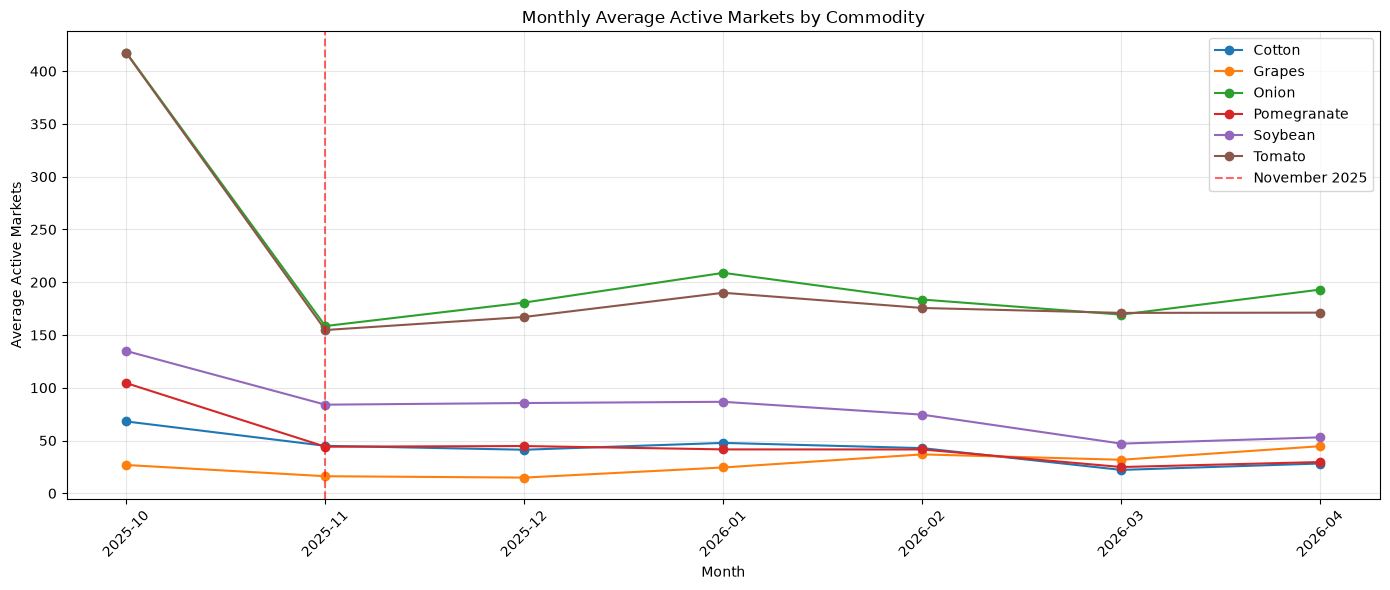

In [ ]:
plt.figure(figsize=(14, 6))

for commodity in monthly_average_market_activity["Project_Commodity"].unique():
    subset = monthly_average_market_activity[
        monthly_average_market_activity["Project_Commodity"] == commodity
    ]

    plt.plot(
        subset["Month"].astype(str),
        subset["Avg_Active_Markets"],
        marker="o",
        label=commodity
    )

plt.axvline(
    x=1,
    color="red",
    linestyle="--",
    alpha=0.6,
    label="November 2025"
)

plt.title("Monthly Average Active Markets by Commodity")
plt.xlabel("Month")
plt.ylabel("Average Active Markets")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

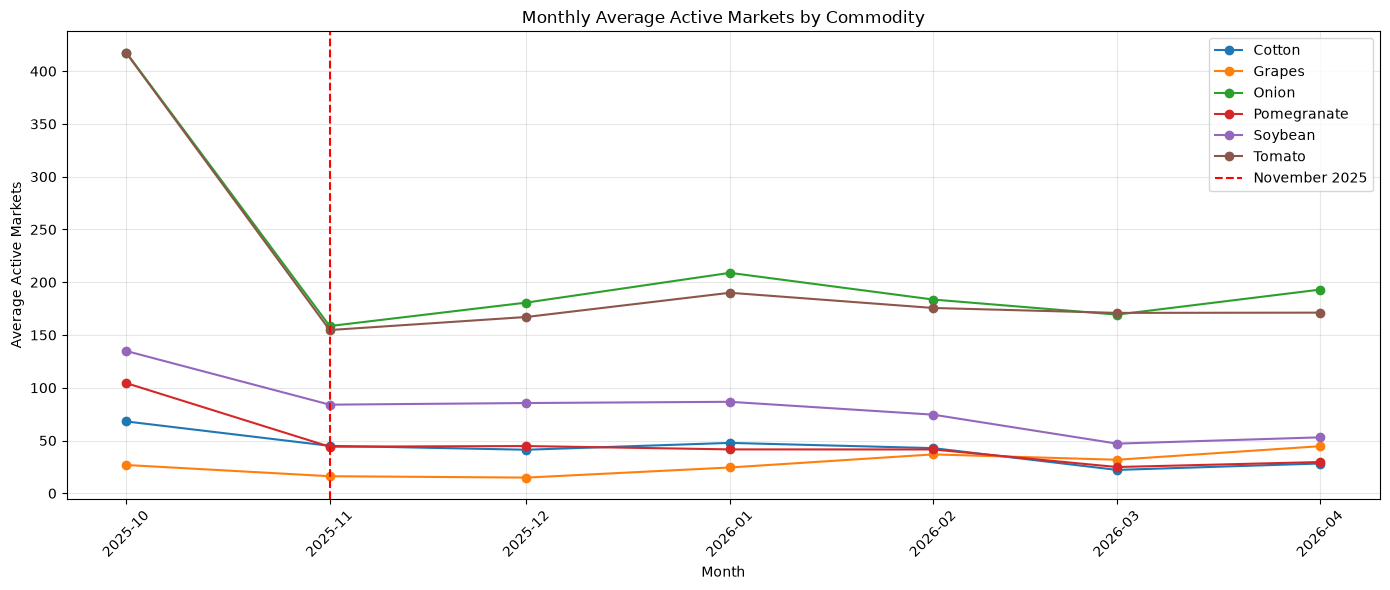

In [ ]:
plot_data = monthly_average_market_activity.copy()
plot_data["Month_Date"] = plot_data["Month"].dt.to_timestamp()

plt.figure(figsize=(14, 6))

for commodity in plot_data["Project_Commodity"].unique():
    subset = plot_data[
        plot_data["Project_Commodity"] == commodity
    ]

    plt.plot(
        subset["Month_Date"],
        subset["Avg_Active_Markets"],
        marker="o",
        label=commodity
    )

plt.axvline(
    pd.Timestamp("2025-11-01"),
    color="red",
    linestyle="--",
    label="November 2025"
)

plt.title("Monthly Average Active Markets by Commodity")
plt.xlabel("Month")
plt.ylabel("Average Active Markets")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()